In [65]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Annotated
from langchain_google_genai import ChatGoogleGenerativeAI
from pydantic import BaseModel,Field
from dotenv import load_dotenv
import operator


In [66]:
load_dotenv()

True

In [67]:
class Structure(BaseModel):
    feedback:str=Field(description="Feedback on the structure of the essay")
    rating:int=Field(description="Rating of the structure of the essay on a scale of 1-10", ge=0 ,le=10)

In [68]:
model=ChatGoogleGenerativeAI(model="gemini-3.1-flash-lite")
structured_model=model.with_structured_output(Structure)

In [69]:
essay = """
Artificial Intelligence is transforming the way people live and work.
It is being used in healthcare, education, transportation, finance,
and many other industries. AI systems can analyze large amounts of
data, identify patterns, and perform tasks that traditionally
required human intelligence.

In healthcare, artificial intelligence helps doctors detect diseases,
analyze medical images, and predict potential health risks. In
education, AI-powered tools provide personalized learning experiences
and help students understand difficult concepts.

Despite its benefits, artificial intelligence also creates challenges.
Privacy, security, job displacement, and ethical concerns must be
carefully considered. Organizations should use AI responsibly and
ensure that its decisions are fair and transparent.

In the future, artificial intelligence is expected to become even
more advanced. It will continue to assist humans in solving complex
problems, improving productivity, and creating new opportunities.
However, human creativity, judgment, and responsibility will remain
important in ensuring that AI is used for the benefit of society.
"""

In [70]:
# prompt=f"Please evaluate the structure of the following essay and provide feedback and a rating on a scale of 1-10: {essay}"
# output = structured_model.invoke(prompt)
# output
# output.feedback
# output.rating



In [71]:
# print("Feedback on the structure of the essay:", output.feedback)
# print("Rating of the structure of the essay (1-10):", output.rating)


In [72]:
class UPSC(TypedDict):
    essay:str
    COT_feedback:str
    DOA_feedback:str
    lang_feedback:str
    final_feedback:str
    individual_scores:Annotated[list[int],operator.add]
    final_score:int

In [73]:
def COT(state:UPSC):
    prompt=f"Please provide a feedback on the following essay evaluating on chain-of-thought: {state['essay']} and provide a rating on a scale of 1-10"
    output = structured_model.invoke(prompt)
    return {
        "COT_feedback": output.feedback,
        "individual_scores":[output.rating]
    }

In [74]:
def DOA(state:UPSC):
    prompt=f"Please provide a feedback on the following essay evaluating on depth of analysis: {state['essay']} and provide a rating on a scale of 1-10"
    output = structured_model.invoke(prompt)
    return {
        "DOA_feedback": output.feedback,
        "individual_scores":[output.rating]
    }

In [75]:
def Language(state:UPSC):
    prompt=f"Please provide a feedback on the following essay evaluating on language use: {state['essay']} and provide a rating on a scale of 1-10"
    output = structured_model.invoke(prompt)
    return {
        "lang_feedback": output.feedback,
        "individual_scores":[output.rating]
    }

In [76]:
def Final(state:UPSC):
    prompt=f"Please provide a final feedback based on essay : {state['essay']} , chain-of-thought : {state['COT_feedback']} , depth-of-analysis : {state['DOA_feedback']} , Language-use : {state['lang_feedback']}"
    output = model.invoke(prompt).content
    return {
        "final_feedback": output,
        "final_score": sum(state['individual_scores'])//len(state['individual_scores'])
    }

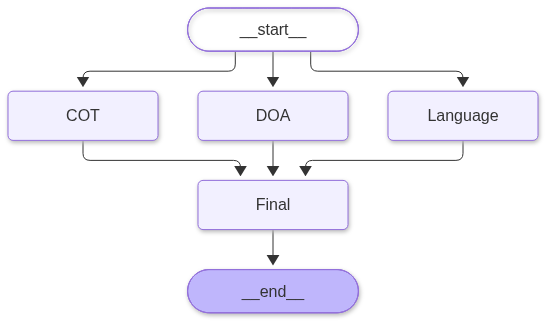

In [77]:
graph=StateGraph(UPSC)

graph.add_node("COT",COT)
graph.add_node("DOA",DOA)
graph.add_node("Language",Language)
graph.add_node("Final",Final)

graph.add_edge(START,"COT")
graph.add_edge(START,"DOA")
graph.add_edge(START,"Language")
graph.add_edge("COT","Final")
graph.add_edge("DOA","Final")
graph.add_edge("Language","Final")
graph.add_edge("Final",END)

workflow=graph.compile()
workflow

In [78]:
initial_state={"essay":essay}
workflow.invoke(initial_state)

{'essay': '\nArtificial Intelligence is transforming the way people live and work.\nIt is being used in healthcare, education, transportation, finance,\nand many other industries. AI systems can analyze large amounts of\ndata, identify patterns, and perform tasks that traditionally\nrequired human intelligence.\n\nIn healthcare, artificial intelligence helps doctors detect diseases,\nanalyze medical images, and predict potential health risks. In\neducation, AI-powered tools provide personalized learning experiences\nand help students understand difficult concepts.\n\nDespite its benefits, artificial intelligence also creates challenges.\nPrivacy, security, job displacement, and ethical concerns must be\ncarefully considered. Organizations should use AI responsibly and\nensure that its decisions are fair and transparent.\n\nIn the future, artificial intelligence is expected to become even\nmore advanced. It will continue to assist humans in solving complex\nproblems, improving productiv